In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# --------------------------------------------------------
# Plot Settings
# --------------------------------------------------------

plt.rcParams["figure.figsize"] = (10,6)
plt.rcParams["figure.dpi"] = 150

# --------------------------------------------------------
# Project Paths
# --------------------------------------------------------

PROJECT_ROOT = Path.cwd().parent

RESULT_DIR = PROJECT_ROOT / "results"

FIGURE_DIR = PROJECT_ROOT / "figures"

# --------------------------------------------------------
# CADWG Parameters
# --------------------------------------------------------

WINDOW = 5

ALPHA = 0.70

BETA = 0.80

print("="*60)
print("Confidence-Adaptive Dynamic Weight Generation")
print("="*60)

print(f"Rolling Window : {WINDOW}")
print(f"Alpha          : {ALPHA}")
print(f"Beta           : {BETA}")

print("="*60)

Confidence-Adaptive Dynamic Weight Generation
Rolling Window : 5
Alpha          : 0.7
Beta           : 0.8


In [2]:
# ============================================================
# Cell 2
# Load Camera Confidence
# ============================================================

DRIVE = "2011_09_26_drive_0001_sync"

confidence_df = pd.read_csv(

    RESULT_DIR /

    f"camera_confidence_{DRIVE}.csv"

)

print("=" * 70)

print("Camera Confidence Dataset Loaded")

print("=" * 70)

print("Drive :", DRIVE)

print("Frames :", len(confidence_df))

print("=" * 70)

display(confidence_df.head())

Camera Confidence Dataset Loaded
Drive : 2011_09_26_drive_0001_sync
Frames : 108


,Brightness,Contrast,Blur,Entropy,Dynamic Range,Edge Density,Noise,Frame,Camera Confidence,Confidence Level
0,0.362415,0.824470,0.122920,0.256092,251,0.176659,0.870587,0,0.373539,Poor
1,0.282173,0.744032,0.107438,0.211880,250,0.181919,0.884934,1,0.338947,Poor
2,0.166911,0.716453,0.087152,0.162473,250,0.199297,0.904427,2,0.307125,Poor
3,0.191004,0.751561,0.086077,0.216606,252,0.232426,0.904300,3,0.331519,Poor
4,0.344544,0.817566,0.136863,0.364507,252,0.274970,0.849263,4,0.407605,Low


In [3]:
print("="*60)

print("Camera Confidence Dataset Summary")

print("="*60)

print(f"Total Frames : {len(confidence_df)}")

print(f"Columns      : {len(confidence_df.columns)}")

print()

display(

confidence_df.describe()

)

Camera Confidence Dataset Summary
Total Frames : 108
Columns      : 10



,Brightness,Contrast,Blur,Entropy,Dynamic Range,Edge Density,Noise,Frame,Camera Confidence
count,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.000000,108.00000,108.000000
mean,0.504872,0.559509,0.422146,0.568500,250.601852,0.375789,0.552321,53.50000,0.490494
std,0.247358,0.298456,0.281896,0.290495,0.975780,0.316425,0.286485,31.32092,0.148791
min,0.000000,0.000000,0.000000,0.000000,248.000000,0.000000,0.000000,0.00000,0.265978
25%,0.306699,0.372807,0.206240,0.276907,250.000000,0.127299,0.267474,26.75000,0.372924
50%,0.485205,0.558423,0.321661,0.637529,251.000000,0.199340,0.645192,53.50000,0.462247
75%,0.696022,0.830769,0.694107,0.829450,251.000000,0.696507,0.758943,80.25000,0.599867
max,1.000000,1.000000,1.000000,1.000000,254.000000,1.000000,1.000000,107.00000,0.816628


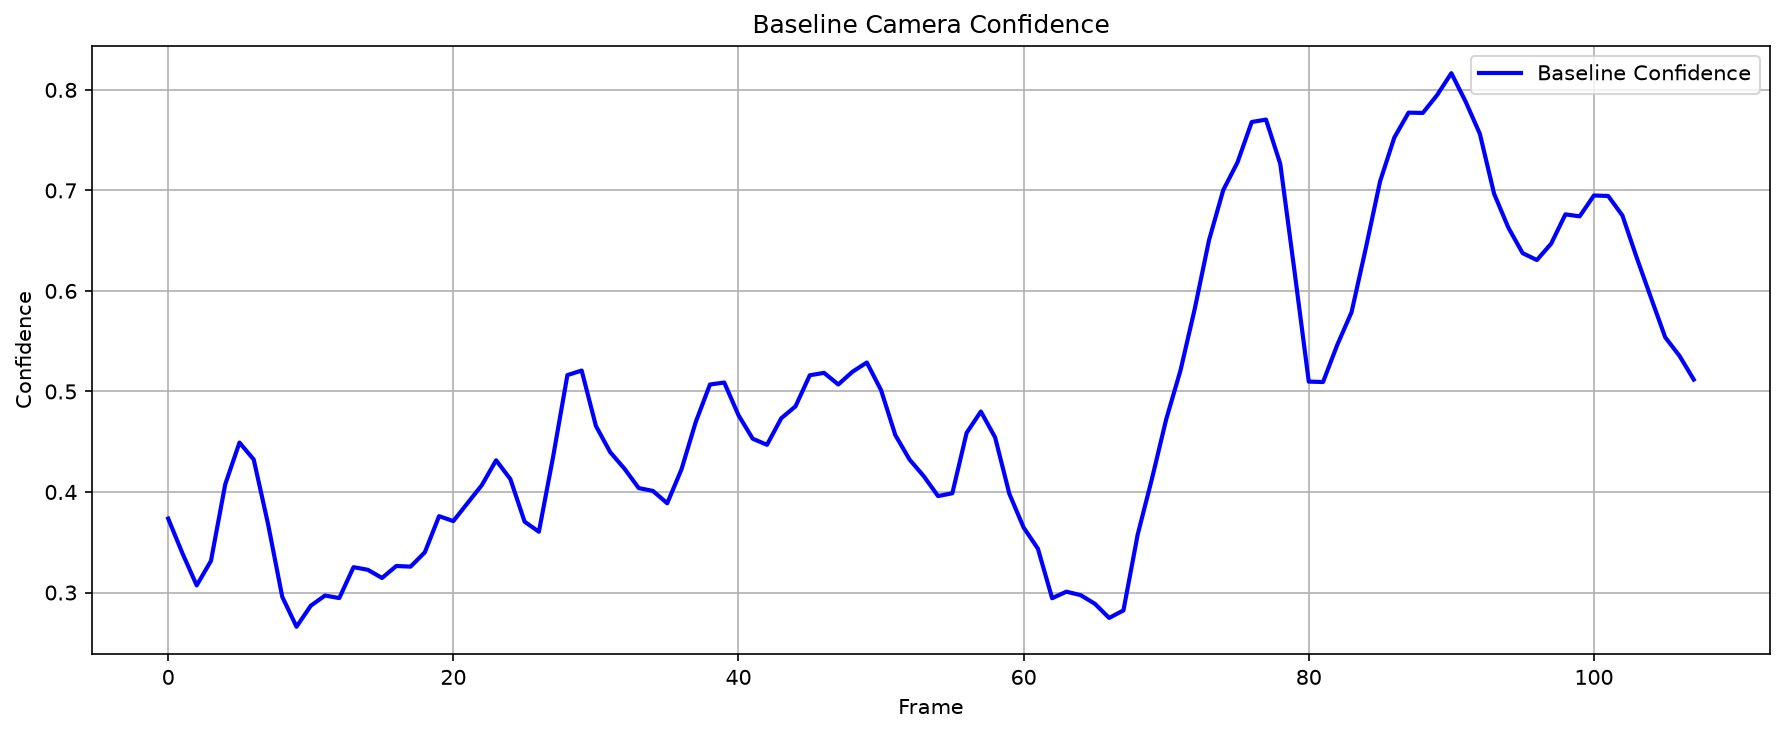

In [4]:
plt.figure(figsize=(12,5))

plt.plot(

    confidence_df["Frame"],

    confidence_df["Camera Confidence"],

    color="blue",

    linewidth=2,

    label="Baseline Confidence"

)

plt.xlabel("Frame")

plt.ylabel("Confidence")

plt.title("Baseline Camera Confidence")

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.savefig(

    FIGURE_DIR /

    "baseline_camera_confidence.png",

    dpi=300

)

plt.show()

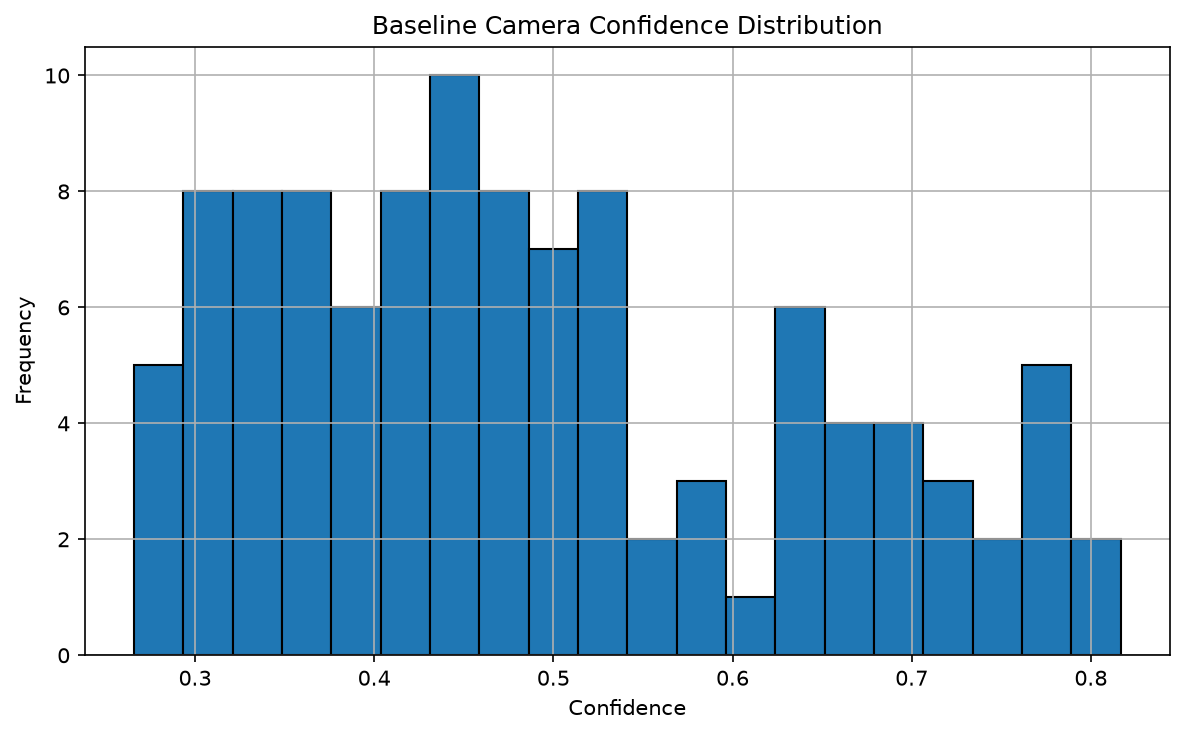

In [5]:
plt.figure(figsize=(8,5))

plt.hist(

    confidence_df["Camera Confidence"],

    bins=20,

    edgecolor="black"

)

plt.xlabel("Confidence")

plt.ylabel("Frequency")

plt.title("Baseline Camera Confidence Distribution")

plt.grid(True)

plt.tight_layout()

plt.savefig(

    FIGURE_DIR /

    "baseline_confidence_distribution.png",

    dpi=300

)

plt.show()

In [6]:
# ============================================================
# Rolling Confidence
# ============================================================

WINDOW = 5

confidence_df["Rolling Confidence"] = (

    confidence_df["Camera Confidence"]

    .rolling(
        window=WINDOW,
        min_periods=1
    )

    .mean()

)

display(

confidence_df[[

"Frame",

"Camera Confidence",

"Rolling Confidence"

]].head()

)

,Frame,Camera Confidence,Rolling Confidence
0,0,0.373539,0.373539
1,1,0.338947,0.356243
2,2,0.307125,0.339870
3,3,0.331519,0.337782
4,4,0.407605,0.351747


In [7]:
# ============================================================
# Temporal Confidence Smoothing + CSI
# ============================================================

ALPHA = 0.40

confidence_df["Smoothed Confidence"] = (

    confidence_df["Rolling Confidence"]

    .ewm(

        alpha=ALPHA,

        adjust=False

    )

    .mean()

)

WINDOW = 5

confidence_df["Confidence Std"] = (

    confidence_df["Smoothed Confidence"]

    .rolling(

        WINDOW,

        min_periods=1

    )

    .std()

)

confidence_df["Confidence Std"] = (

    confidence_df["Confidence Std"]aa

    .fillna(0)

)

confidence_df["Normalized Std"] = (

    confidence_df["Confidence Std"]

    -

    confidence_df["Confidence Std"].min()

) / (

    confidence_df["Confidence Std"].max()

    -

    confidence_df["Confidence Std"].min()

    +

    1e-8

)

confidence_df["Confidence Stability Index"] = (

    1 -

    confidence_df["Normalized Std"]

)

display(

confidence_df[[

    "Frame",

    "Rolling Confidence",

    "Smoothed Confidence",

    "Confidence Stability Index"

]].head()

)

print("=" * 70)

print("Temporal Confidence Smoothing Completed")

print("CSI Computed Successfully")

print("=" * 70)

SyntaxError: invalid syntax. Perhaps you forgot a comma? (1694930519.py, line 43)

In [ ]:
# ============================================================
# Sensor Reliability Index
# ============================================================

BETA = 0.80

confidence_df["Sensor Reliability Index"] = (

      BETA

      * confidence_df["Smoothed Confidence"]

    +

      (1-BETA)

      * confidence_df["Confidence Stability Index"]

)

display(

confidence_df[[

"Frame",

"Smoothed Confidence",

"Confidence Stability Index",

"Sensor Reliability Index"

]].head()

)

In [ ]:
# ============================================================
# Camera Adaptive Weight
# ============================================================

confidence_df["Camera Adaptive Weight"] = (

    confidence_df["Sensor Reliability Index"]

)

display(

confidence_df[[

"Frame",

"Camera Adaptive Weight"

]].head()

)

In [ ]:
# ============================================================
# Camera Adaptive Weight Change
# ============================================================

confidence_df["Camera Adaptive Weight Change"] = (

    confidence_df["Camera Adaptive Weight"]

    .diff()

)

confidence_df["Camera Adaptive Weight Change"] = (

    confidence_df["Camera Adaptive Weight Change"]

    .fillna(0)

)

print("="*60)
print("Camera Adaptive Weight Change Computed")
print("="*60)

display(

confidence_df[[

"Frame",

"Camera Adaptive Weight",

"Camera Adaptive Weight Change"

]].head()

)

In [ ]:
comparison = []

windows = [3,5,10]

for w in windows:

    rolling = (

        confidence_df["Camera Confidence"]

        .rolling(

            window=w,

            min_periods=1

        )

        .mean()

    )

    comparison.append({

        "Rolling Window": w,

        "Average Confidence": rolling.mean(),

        "Standard Deviation": rolling.std(),

        "Minimum": rolling.min(),

        "Maximum": rolling.max()

    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df)

In [ ]:
plt.figure(figsize=(12,6))

plt.plot(

    confidence_df["Frame"],

    confidence_df["Camera Confidence"],

    label="Baseline"

)

plt.plot(

    confidence_df["Frame"],

    confidence_df["Rolling Confidence"],

    label="Rolling"

)

plt.plot(

    confidence_df["Frame"],

    confidence_df["Smoothed Confidence"],

    label="Smoothed"

)

plt.plot(

    confidence_df["Frame"],

    confidence_df["Sensor Reliability Index"],

    linewidth=3,

    label="SRI"

)

plt.xlabel("Frame")

plt.ylabel("Confidence")

plt.title("Confidence Evolution")

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.savefig(

    FIGURE_DIR/

    "confidence_evolution.png",

    dpi=300

)

plt.show()

In [ ]:
plt.figure(figsize=(12,5))

plt.plot(

    confidence_df["Frame"],

    confidence_df["Camera Adaptive Weight"],

    linewidth=2

)

plt.xlabel("Frame")

plt.ylabel("Weight")

plt.title("Camera Adaptive Weight")

plt.grid(True)

plt.tight_layout()

plt.savefig(

    FIGURE_DIR/

    "camera_adaptive_weight.png",

    dpi=300

)

plt.show()

In [ ]:
confidence_df["Camera Adaptive Weight Change"] = (

    confidence_df["Camera Adaptive Weight"]

    .diff()

)

confidence_df["Camera Adaptive Weight Change"] = (

    confidence_df["Camera Adaptive Weight Change"]

    .fillna(0)

)

confidence_df["Absolute Weight Change"] = (

    confidence_df["Camera Adaptive Weight Change"]

    .abs()

)

plt.figure(figsize=(12,5))

plt.plot(

    confidence_df["Frame"],

    confidence_df["Absolute Weight Change"]

)

plt.title("Absolute Camera Weight Change")

plt.xlabel("Frame")

plt.ylabel("|Δ Weight|")

plt.grid(True)

plt.tight_layout()

plt.savefig(

    FIGURE_DIR/

    "camera_weight_change.png",

    dpi=300

)

plt.show()

In [ ]:
plt.figure(figsize=(12,5))

plt.plot(

    confidence_df["Frame"],

    confidence_df["Camera Adaptive Weight Change"],

    linewidth=2,

    color="red"

)

plt.xlabel("Frame")

plt.ylabel("Weight Change")

plt.title("Camera Adaptive Weight Change")

plt.grid(True)

plt.tight_layout()

plt.savefig(

    FIGURE_DIR /

    "camera_weight_change.png",

    dpi=300

)

plt.show()

In [ ]:
confidence_df["Absolute Weight Change"] = (

    confidence_df["Camera Adaptive Weight Change"]

    .abs()

)

plt.figure(figsize=(12,5))

plt.plot(

    confidence_df["Frame"],

    confidence_df["Absolute Weight Change"],

    linewidth=2,

    color="purple"

)

plt.xlabel("Frame")

plt.ylabel("|Δ Weight|")

plt.title("Absolute Camera Adaptive Weight Change")

plt.grid(True)

plt.tight_layout()

plt.savefig(

    FIGURE_DIR /

    "absolute_camera_weight_change.png",

    dpi=300

)

plt.show()

In [ ]:
statistics = confidence_df[[

"Camera Confidence",

"Rolling Confidence",

"Smoothed Confidence",

"Confidence Stability Index",

"Sensor Reliability Index",

"Camera Adaptive Weight",

"Absolute Weight Change"

]].describe()

display(statistics)

In [ ]:
summary_table = pd.DataFrame({

"Metric":[

"Average Camera Confidence",

"Average Smoothed Confidence",

"Average CSI",

"Average SRI",

"Average Camera Weight",

"Maximum Camera Weight",

"Minimum Camera Weight",

"Average Weight Change"

],

"Value":[

confidence_df["Camera Confidence"].mean(),

confidence_df["Smoothed Confidence"].mean(),

confidence_df["Confidence Stability Index"].mean(),

confidence_df["Sensor Reliability Index"].mean(),

confidence_df["Camera Adaptive Weight"].mean(),

confidence_df["Camera Adaptive Weight"].max(),

confidence_df["Camera Adaptive Weight"].min(),

confidence_df["Absolute Weight Change"].mean()

]

})

display(summary_table)

In [ ]:
statistics = confidence_df[[

    "Camera Confidence",

    "Rolling Confidence",

    "Smoothed Confidence",

    "Confidence Stability Index",

    "Sensor Reliability Index",

    "Camera Adaptive Weight",

    "Camera Adaptive Weight Change",

    "Absolute Weight Change"

]].describe()

display(statistics)

In [ ]:
summary_table = pd.DataFrame({

    "Metric":[

        "Average Camera Confidence",

        "Average Smoothed Confidence",

        "Average CSI",

        "Average SRI",

        "Average Camera Weight",

        "Maximum Camera Weight",

        "Minimum Camera Weight",

        "Average Weight Change"

    ],

    "Value":[

        confidence_df["Camera Confidence"].mean(),

        confidence_df["Smoothed Confidence"].mean(),

        confidence_df["Confidence Stability Index"].mean(),

        confidence_df["Sensor Reliability Index"].mean(),

        confidence_df["Camera Adaptive Weight"].mean(),

        confidence_df["Camera Adaptive Weight"].max(),

        confidence_df["Camera Adaptive Weight"].min(),

        confidence_df["Absolute Weight Change"].mean()

    ]

})

display(summary_table)

In [ ]:
# ============================================================
# Save Main Results
# ============================================================

confidence_df.to_csv(

    RESULT_DIR /

    "dynamic_weight_generation.csv",

    index=False

)

# ============================================================
# Save Statistics
# ============================================================

statistics.to_csv(

    RESULT_DIR /

    "dynamic_weight_statistics.csv"

)

# ============================================================
# Save Window Comparison
# ============================================================

comparison_df.to_csv(

    RESULT_DIR /

    "window_comparison.csv",

    index=False

)

# ============================================================
# Save Summary Table
# ============================================================

summary_table.to_csv(

    RESULT_DIR /

    "cadwg_summary.csv",

    index=False

)

# ============================================================
# Save Parameters
# ============================================================

parameter_df = pd.DataFrame({

    "Parameter":[

        "Rolling Window",

        "Alpha",

        "Beta"

    ],

    "Value":[

        WINDOW,

        ALPHA,

        BETA

    ]

})

parameter_df.to_csv(

    RESULT_DIR /

    "cadwg_parameters.csv",

    index=False

)

print("="*60)
print("All results successfully saved.")
print("="*60)

In [ ]:
# ============================================================
# Cell 23
# Save Results
# ============================================================

confidence_df.to_csv(

    RESULT_DIR /

    f"dynamic_weight_generation_{DRIVE}.csv",

    index=False

)

statistics.to_csv(

    RESULT_DIR /

    f"dynamic_weight_statistics_{DRIVE}.csv"

)

comparison_df.to_csv(

    RESULT_DIR /

    f"window_comparison_{DRIVE}.csv",

    index=False

)

summary_table.to_csv(

    RESULT_DIR /

    f"cadwg_summary_{DRIVE}.csv",

    index=False

)

parameter_df = pd.DataFrame({

    "Parameter":[

        "Rolling Window",

        "Alpha",

        "Beta"

    ],

    "Value":[

        WINDOW,

        ALPHA,

        BETA

    ]

})

parameter_df.to_csv(

    RESULT_DIR /

    f"cadwg_parameters_{DRIVE}.csv",

    index=False

)

print("=" * 70)

print("CADWG Results Saved Successfully")

print("=" * 70)

print(f"dynamic_weight_generation_{DRIVE}.csv")

print(f"dynamic_weight_statistics_{DRIVE}.csv")

print(f"window_comparison_{DRIVE}.csv")

print(f"cadwg_summary_{DRIVE}.csv")

print(f"cadwg_parameters_{DRIVE}.csv")

print("=" * 70)

In [ ]:
# ============================================================
# Cell 24
# Notebook Summary
# ============================================================

print("=" * 80)

print("NOTEBOOK 06 COMPLETED SUCCESSFULLY")

print("=" * 80)

print()

print("Drive :", DRIVE)

print()

print("CADWG PIPELINE")

print("----------------------------")

print("Camera Confidence")

print("      ↓")

print("Rolling Confidence")

print("      ↓")

print("Temporal Confidence Smoothing")

print("      ↓")

print("Confidence Stability Index")

print("      ↓")

print("Sensor Reliability Index")

print("      ↓")

print("Camera Adaptive Weight")

print()

print(f"Total Frames                 : {len(confidence_df)}")

print(f"Rolling Window               : {WINDOW}")

print(f"Alpha                        : {ALPHA}")

print(f"Beta                         : {BETA}")

print()

print(f"Average Camera Confidence    : {confidence_df['Camera Confidence'].mean():.3f}")

print(f"Average Smoothed Confidence  : {confidence_df['Smoothed Confidence'].mean():.3f}")

print(f"Average CSI                  : {confidence_df['Confidence Stability Index'].mean():.3f}")

print(f"Average SRI                  : {confidence_df['Sensor Reliability Index'].mean():.3f}")

print(f"Average Camera Weight        : {confidence_df['Camera Adaptive Weight'].mean():.3f}")

print()

print("Generated Files")

print("----------------------------")

print(f"dynamic_weight_generation_{DRIVE}.csv")

print(f"dynamic_weight_statistics_{DRIVE}.csv")

print(f"window_comparison_{DRIVE}.csv")

print(f"cadwg_summary_{DRIVE}.csv")

print(f"cadwg_parameters_{DRIVE}.csv")

print()

print("READY FOR NOTEBOOK 07")

print("=" * 80)

In [8]:
print(confidence_df.columns.tolist())

['Brightness', 'Contrast', 'Blur', 'Entropy', 'Dynamic Range', 'Edge Density', 'Noise', 'Frame', 'Camera Confidence', 'Confidence Level', 'Rolling Confidence']
